# 03 · Exploratory Data Analysis (Step 8)

**Purpose:** understand the validated historical data **before** defining the prediction target and features.

**Read-only and descriptive.** All numbers come from `src/eda.py`, which reads the validated interim tables, converts values in memory only, and writes `outputs/tables/eda_*.csv` (31 tables) and `outputs/figures/eda/*.png` (19 figures). Every figure has a table twin.

**Not done here:** targets, features, splits, imputation, models, feature selection.

**Leakage labels.** T0 = the official starting grid is final, before the formation lap. Outcome variables (`position`, `points`, `laps`, `status`, times, fastest laps, result categories) are described here but are **POST-RACE** and must never become inputs. See Section 1.

**Weather caveat.** Weather is historical **reanalysis**, not a forecast. Windows are aligned to: **1950–2004 an assumed 14:00 local start**; **2005–2006 the P-12 local-clock interpretation**; **2007–2025 official UTC start times**. Race-window weather is observed *during* the race, i.e. a perfect-forecast proxy.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "config.yaml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from importlib.metadata import version
pins = dict(l.split("==") for l in (PROJECT_ROOT / "requirements.txt").read_text().splitlines() if "==" in l and not l.startswith("#"))
assert version("pandas") == pins["pandas"], "select the 'Python 3.11 (f1-race-prediction)' kernel"

from src.config import load_config
from src import eda

CONFIG = load_config()
TABLES = PROJECT_ROOT / CONFIG["paths"]["tables"]
FIGS = PROJECT_ROOT / CONFIG["paths"]["figures"] / "eda"
T = eda.run(PROJECT_ROOT / CONFIG["paths"]["data_interim"], TABLES, FIGS)   # read-only; deterministic
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)

def tbl(name):
    return T[name]

def fig(name):
    display(Image(filename=str(FIGS / f"{name}.png")))

print(len(T), "tables,", len(list(FIGS.glob("*.png"))), "figures")

31 tables, 19 figures


## 1. Variable roles: what is known at T0 and what is an outcome

Source type: **raw** (API), **policy-derived** (approved P-01…P-12), or **descriptive EDA variable** (in memory only). Timing is the leakage label.

In [2]:
tbl("eda_variable_roles").groupby("timing")["column"].apply(lambda c: ", ".join(c)).to_frame("columns")

,columns
timing,
DURING RACE (oracle-forecast proxy),"wx_race_temp_mean_c, wx_race_humidity_mean_pct, wx_race_precip_sum_mm, wx_ra..."
POST-RACE (uses position),is_primary_entry
POST-RACE OUTCOME,"position, position_text, points, laps, status, time_millis, time_text, faste..."
metadata,"start_time_source, p12_local_clock_applied, timezone, grid_distance_km"
not historical,permanent_number
"observed before T0 (reanalysis, not a forecast)","wx_prestart_temp_mean_c, wx_prestart_humidity_mean_pct, wx_prestart_precip_s..."
population filter,"is_indianapolis_500, in_model_population"
population filter (T0),started
pre-race,era


## 2. Dataset overview

In [3]:
tbl("eda_dataset_overview")

,metric,value,note
0,seasons,76.0,1950-2025
1,races,1149.0,all collected
2,"Indianapolis 500 races (excluded, P-11)",11.0,1950-1960
3,eligible races,1138.0,
4,result rows (all entries),25873.0,
5,model-population rows (P-08),25066.0,"started, primary entry, not Indy 500"
6,qualifying rows,10973.0,"1994-2025, gaps 1994-2002"
7,sprint rows,480.0,2021-2025
8,drivers with results,817.0,
9,drivers in model population,687.0,


In [4]:
tbl("eda_era_summary").T

,0,1,2,3
era,1950-1969,1970-1989,1990-2009,2010-2025
seasons,20,20,20,16
races,184,300,336,329
eligible_races,173,300,336,329
model_rows,3356,7364,7476,6870
mean_starters_per_race,19.399,24.547,22.25,20.881
drivers_per_season,46.75,39.8,28.35,23.125
constructors_per_season,12.3,16.25,12.1,10.562
"dnf_rate_pct (started, not classified)",45.381,48.099,37.681,14.949
disqualified_pct,0.417,1.1,0.615,0.291


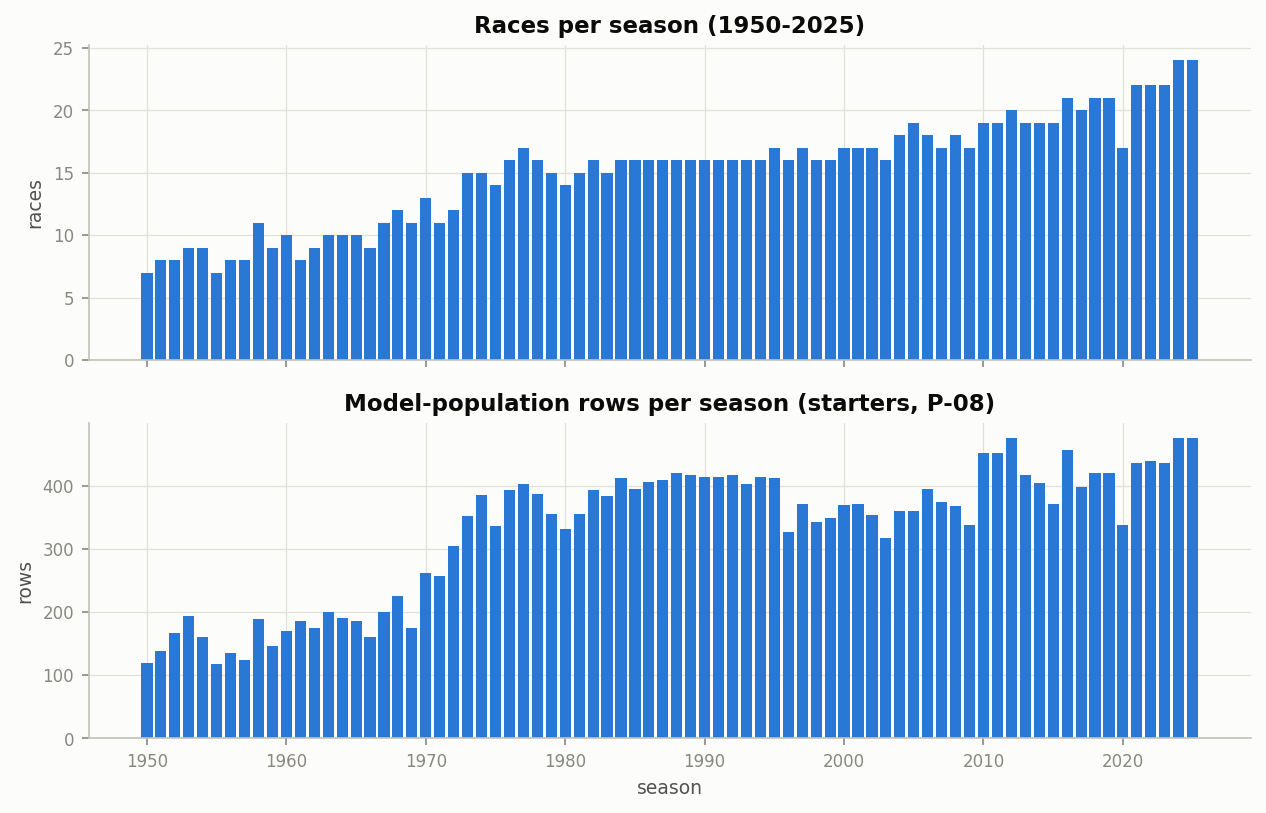

In [5]:
fig("eda_01_races_and_rows_per_season")

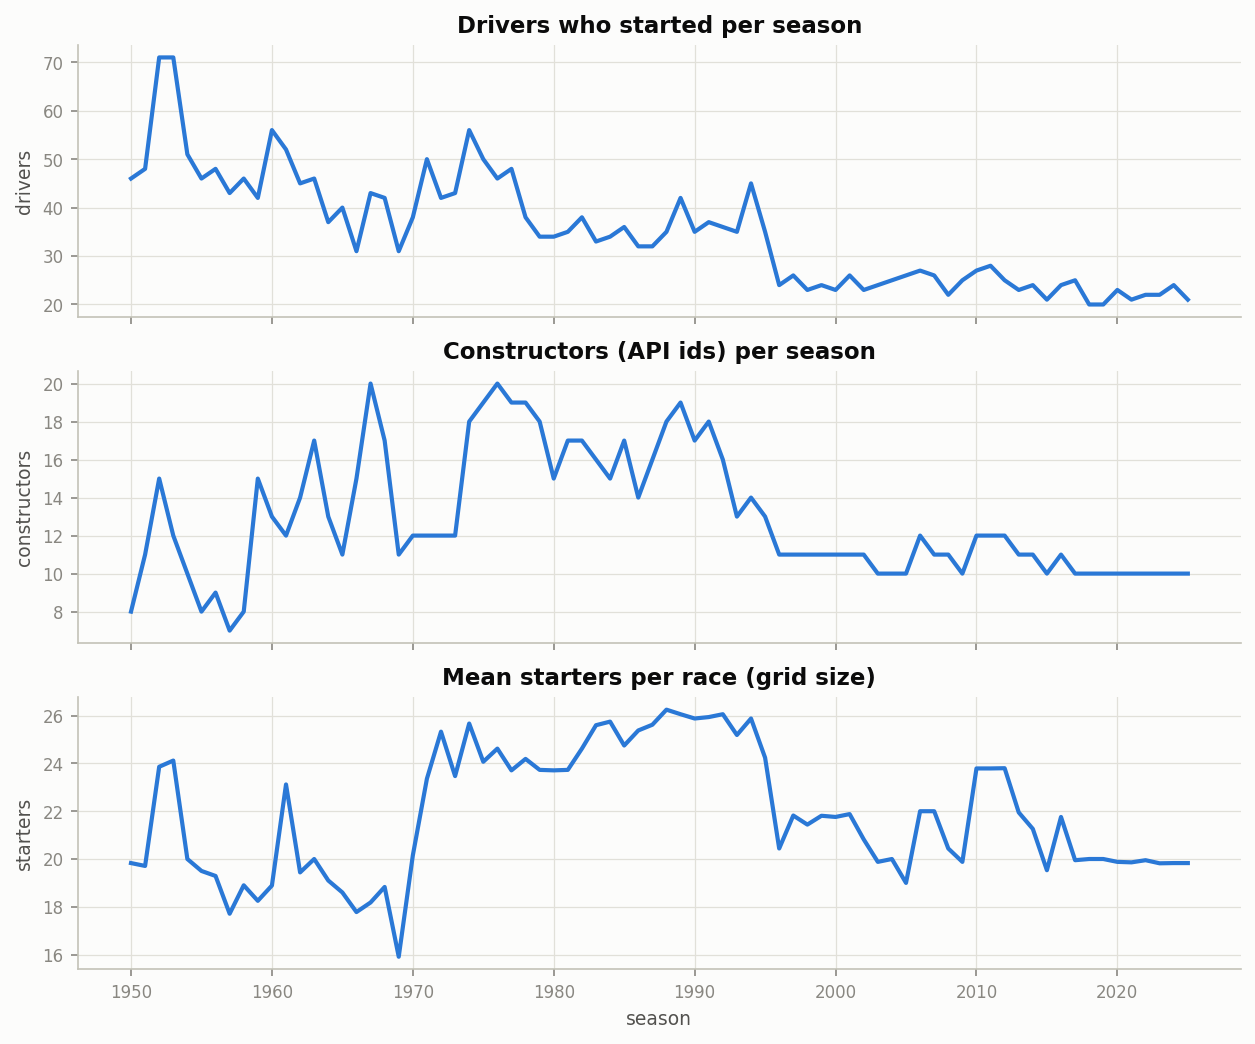

In [6]:
fig("eda_02_drivers_constructors_grid_size")

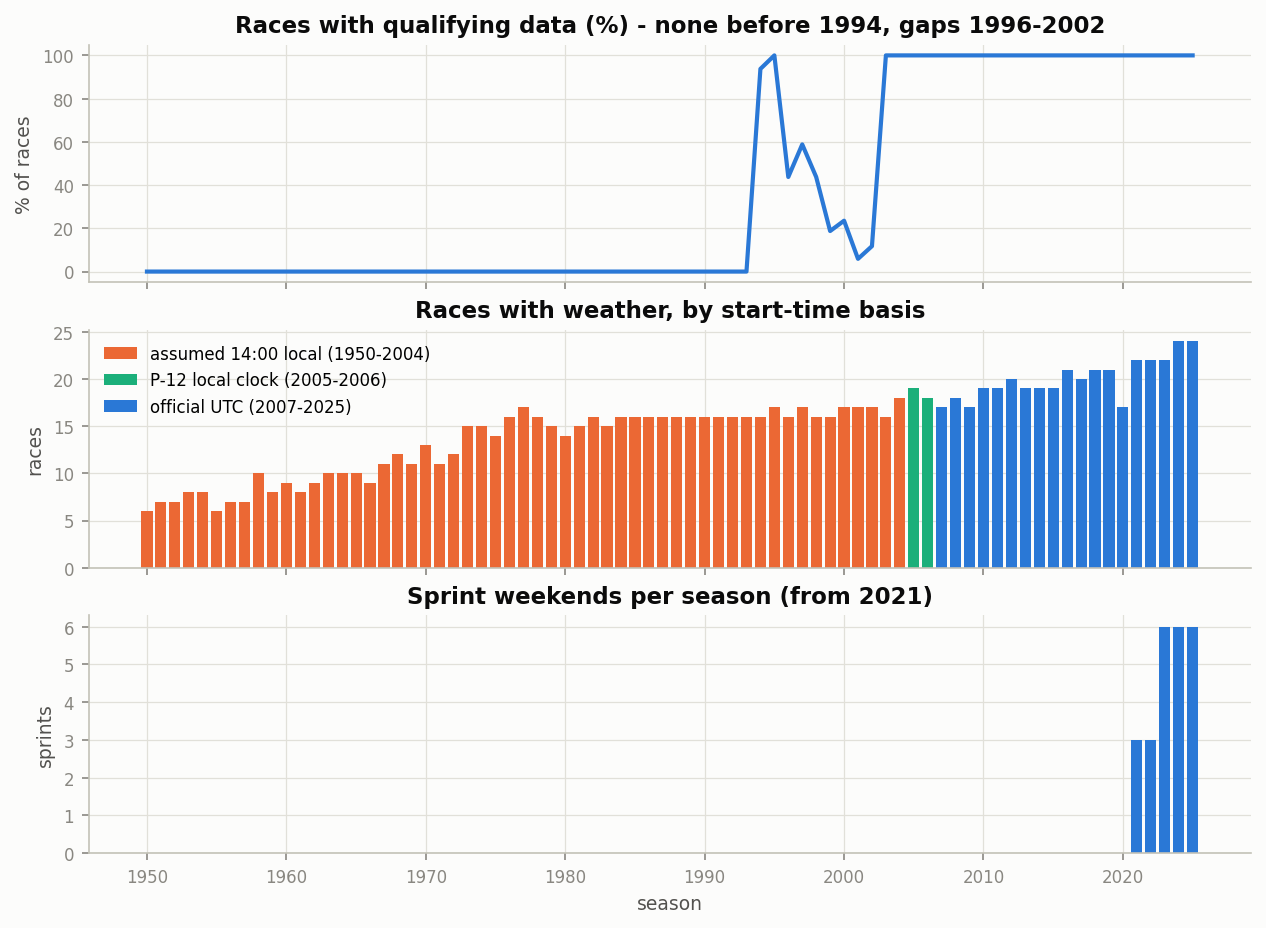

In [7]:
fig("eda_03_data_availability_by_season")

**Reading:** the calendar grew from 6–8 races (1950s) to 24 (2024–2025). Grid size peaked in the 1970s–80s (≈ 24.5 starters per race) and is ≈ 20–21 today. Fewer drivers per season now (23 vs 47 in 1950–69) because one-off entries disappeared. Qualifying data starts in 1994 with gaps until 2002; sprints exist only from 2021.

In [8]:
tbl("eda_representative_seasons")

,season,races,mean_starters_per_race,dnf_rate_pct,pole_win_rate_pct,mean_abs_position_change_classified,races_with_qualifying,races_with_race_precip_ge_0_1mm,constructors,drivers
0,1955,7,19.50,43.59,37.50,4.47,0,1,8,46
1,1975,14,24.07,41.54,30.77,5.90,0,8,19,50
2,1995,17,24.24,48.54,29.41,4.79,17,5,13,35
3,2015,19,19.53,18.06,63.16,2.95,19,6,10,21
4,2024,24,19.83,9.03,45.83,2.57,24,6,10,24


## 3. Missing data (no imputation)

In [9]:
tbl("eda_missingness")

,table,field,rows,missing,missing_pct,historically_unavailable,structurally_absent,legitimately_absent,unexpected_missing,rule
0,results,grid,25873,0,0.000,0,0,0,0,
1,results,position,25873,0,0.000,0,0,0,0,
2,results,position_text,25873,0,0.000,0,0,0,0,
3,results,status,25873,0,0.000,0,0,0,0,
4,results,laps,25873,0,0.000,0,0,0,0,
5,results,points,25873,0,0.000,0,0,0,0,
6,results,time_millis,25873,17545,67.812,0,0,17544,1,race time only for cars finishing on the lead lap
7,results,fastest_lap_rank,25873,17148,66.278,16748,0,380,20,fastest lap data only from 2004 (and not for every field/season); none if <=...
8,results,fastest_lap_lap,25873,17148,66.278,16748,0,380,20,fastest lap data only from 2004 (and not for every field/season); none if <=...
9,results,fastest_lap_time,25873,17148,66.278,16748,0,380,20,fastest lap data only from 2004 (and not for every field/season); none if <=...


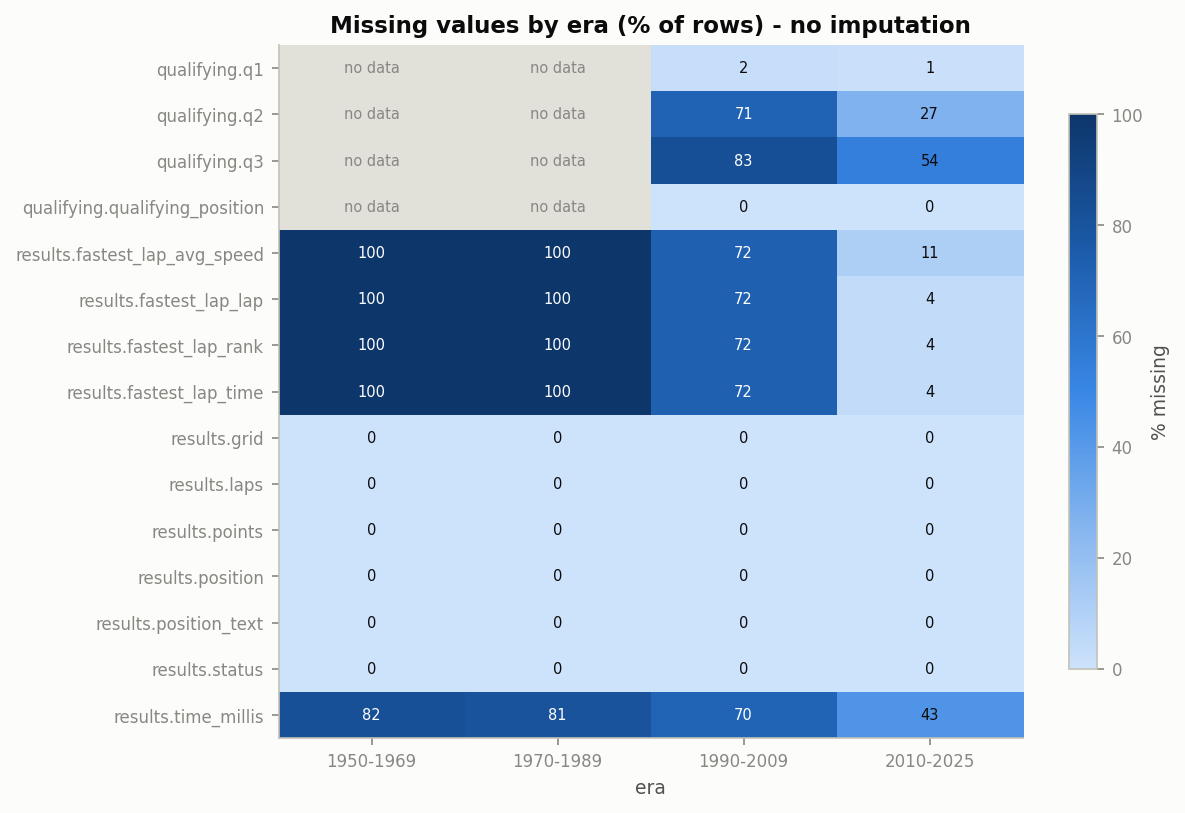

In [10]:
fig("eda_04_missingness_by_era")

### The 286 unexpected missing values from Step 7

In [11]:
tbl("eda_unexpected_missing")

,field,table,values,seasons,races,example,possible_explanation,handle_later
0,driver_dob,drivers,14,2025-2025,0,Paul Aron: dob/nationality missing in API,season-list drivers without date of birth in the API (little-known entrants),"Yes, if driver age becomes a candidate variable: leave missing + indicator"
1,driver_nationality,drivers,14,2025-2025,0,Paul Aron: dob/nationality missing in API,same 14 drivers without nationality,Only if nationality is ever used
2,fastest_lap_avg_speed,results,47,2007-2024,22,"results.fastest_lap_avg_speed missing (status Accident, laps 2)","API omits fastest-lap data for some classified cars in some 2004+ races, and...",No: fastest-lap fields are POST-RACE outcomes and will never be inputs
3,fastest_lap_lap,results,20,2007-2025,16,"results.fastest_lap_lap missing (status Accident, laps 2)","API omits fastest-lap data for some classified cars in some 2004+ races, and...",No: fastest-lap fields are POST-RACE outcomes and will never be inputs
4,fastest_lap_lap,sprints,2,2023-2023,2,"sprints.fastest_lap_lap missing (status Collision damage, laps 2)","API omits fastest-lap data for some classified cars in some 2004+ races, and...",No: fastest-lap fields are POST-RACE outcomes and will never be inputs
5,fastest_lap_rank,results,20,2007-2025,16,"results.fastest_lap_rank missing (status Accident, laps 2)","API omits fastest-lap data for some classified cars in some 2004+ races, and...",No: fastest-lap fields are POST-RACE outcomes and will never be inputs
6,fastest_lap_rank,sprints,98,2023-2023,5,"sprints.fastest_lap_rank missing (status Finished, laps 17)","API omits fastest-lap data for some classified cars in some 2004+ races, and...",No: fastest-lap fields are POST-RACE outcomes and will never be inputs
7,fastest_lap_speed_units,results,47,2007-2024,22,"results.fastest_lap_speed_units missing (status Accident, laps 2)","API omits fastest-lap data for some classified cars in some 2004+ races, and...",No: fastest-lap fields are POST-RACE outcomes and will never be inputs
8,fastest_lap_time,results,20,2007-2025,16,"results.fastest_lap_time missing (status Accident, laps 2)","API omits fastest-lap data for some classified cars in some 2004+ races, and...",No: fastest-lap fields are POST-RACE outcomes and will never be inputs
9,fastest_lap_time,sprints,2,2023-2023,2,"sprints.fastest_lap_time missing (status Collision damage, laps 2)","API omits fastest-lap data for some classified cars in some 2004+ races, and...",No: fastest-lap fields are POST-RACE outcomes and will never be inputs


**Reading:** 258 of the 286 are **post-race** fastest-lap or race-time fields (never inputs, so no action needed). The other 28 are 14 drivers (2025 season list, e.g. Paul Aron) without date of birth and nationality. These only matter if driver age becomes a candidate variable.

## 4. Race results (POST-RACE outcomes, described only)

In [12]:
tbl("eda_status_categories").query("era == 'all'")

,era,result_category,rows,share_of_all_rows_pct,share_of_starters_pct
0,all,finished,15554,60.117,60.912
1,all,classified_not_running,678,2.620,2.655
2,all,started_not_classified,9141,35.330,35.798
3,all,disqualified,162,0.626,0.634
4,all,did_not_start,338,1.306,NaN


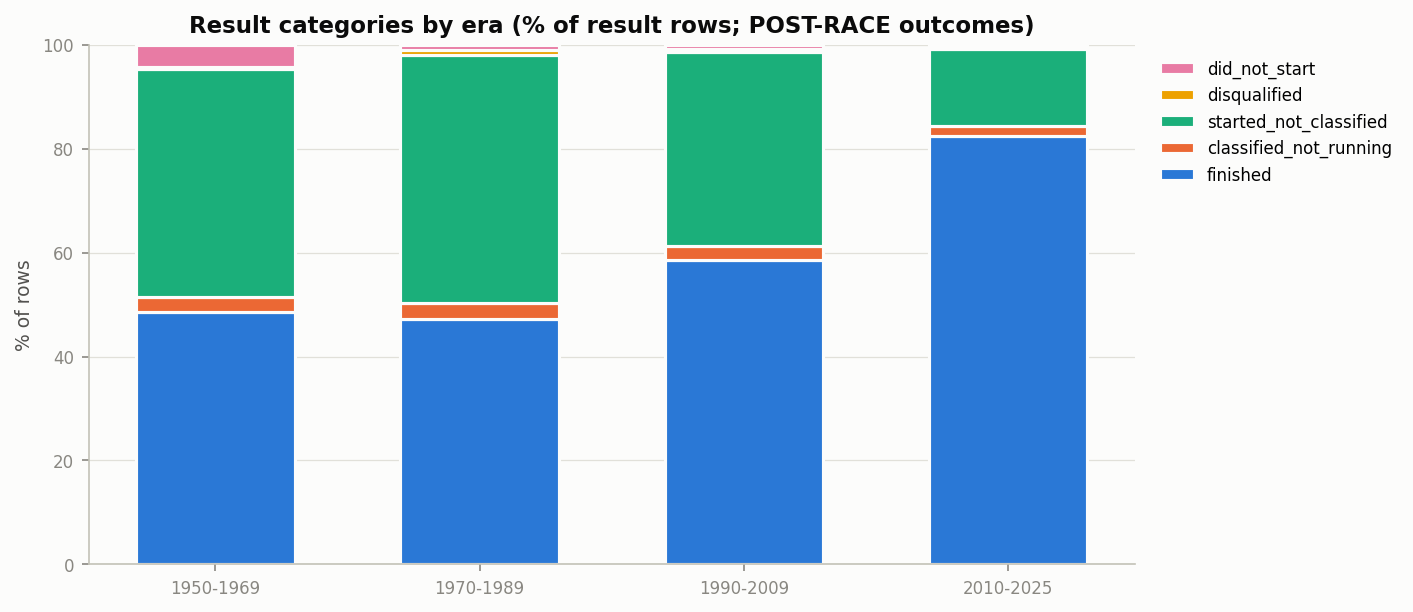

In [13]:
fig("eda_05_result_categories_by_era")

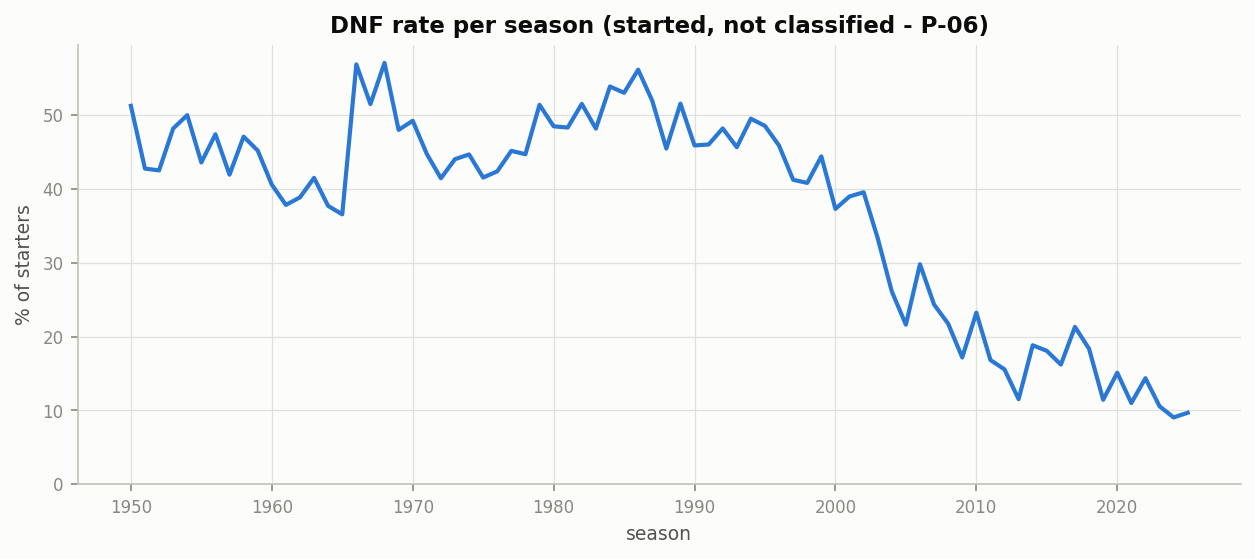

In [14]:
fig("eda_06_dnf_rate_by_season")

In [15]:
tbl("eda_status_top_by_era").query('rank <= 5')

,era,rank,status,rows
0,1950-1969,1,Finished,701
1,1950-1969,2,Engine,460
2,1950-1969,3,+1 Lap,293
3,1950-1969,4,Accident,251
4,1950-1969,5,+2 Laps,213
10,1970-1989,1,Finished,1428
11,1970-1989,2,+1 Lap,932
12,1970-1989,3,Engine,838
13,1970-1989,4,+2 Laps,549
14,1970-1989,5,Accident,497


In [16]:
tbl("eda_position_change")

,era,population,rows,mean_change,median_change,std_change,gained_pct,same_pct,lost_pct
0,all,"classified (finished + classified_not_running), grid > 0",15956,2.932,2.0,4.973,67.260,12.133,20.607
1,all,"all starters, grid > 0 (official position incl. DNF order)",25001,0.063,1.0,7.023,51.330,9.536,39.134
2,1950-1969,"classified (finished + classified_not_running), grid > 0",1819,3.783,4.0,4.630,75.371,10.555,14.074
3,1950-1969,"all starters, grid > 0 (official position incl. DNF order)",3356,0.276,1.0,6.732,52.563,8.284,39.154
4,1970-1989,"classified (finished + classified_not_running), grid > 0",3741,4.868,5.0,5.732,77.118,7.565,15.317
5,1970-1989,"all starters, grid > 0 (official position incl. DNF order)",7354,0.044,1.0,8.436,51.945,6.051,42.004
6,1990-2009,"classified (finished + classified_not_running), grid > 0",4613,3.128,2.0,4.758,69.976,12.031,17.993
7,1990-2009,"all starters, grid > 0 (official position incl. DNF order)",7470,0.034,1.0,6.987,52.209,9.344,38.447
8,2010-2025,"classified (finished + classified_not_running), grid > 0",5783,1.255,1.0,4.087,56.165,15.667,28.169
9,2010-2025,"all starters, grid > 0 (official position incl. DNF order)",6821,0.011,0.0,5.316,49.098,14.118,36.783


In [17]:
tbl("eda_points_laps")

,era,starters,scoring_share_pct,mean_points_per_start,max_points_single_race,median_laps_completed_ratio,mean_laps_ratio_finished,mean_laps_ratio_classified_not_running,mean_laps_ratio_started_not_classified,mean_laps_ratio_disqualified
0,1950-1969,3356,29.738,1.256,9.0,0.875,0.957,0.817,0.358,0.582
1,1970-1989,7364,24.348,1.011,9.0,0.906,0.980,0.933,0.385,0.562
2,1990-2009,7476,30.230,1.376,10.0,0.972,0.987,0.932,0.387,0.738
3,2010-2025,6870,47.889,4.861,50.0,1.000,0.992,0.924,0.371,0.747


**Reading:** DNF (started, not classified) fell from ≈ 45–48% of starters (1950–1989) to ≈ 15% (2010–2025). Classified finishers gain on average 2.9 places from their grid slot. That is mostly a survivorship effect, because retirements ahead of them move them up; it is not evidence of overtaking skill. Points scales changed (max 9–10 before 2010, 25+ later), so raw points are not comparable across eras.

## 5. Drivers

In [18]:
tbl("eda_driver_summary")

,metric,value
0,drivers in model population,687.0
1,drivers listed but never in any result,62.0
2,drivers with result rows but never started,27.0
3,median starts per driver,10.0
4,drivers with 1 start,140.0
5,drivers with >= 100 starts,82.0
6,drivers with at least one win,105.0
7,drivers with a multi-entry race (P-01),29.0
8,drivers with shared-position rows (P-02),66.0
9,new drivers first seen in 1950-1969,331.0


In [19]:
tbl("eda_driver_stats").head(10)

,driver_id,name,first_season,last_season,seasons,starts,wins,podiums,dnfs,points_all_entries (P-01 sum),result_rows_all_entries,non_starts,races_with_multiple_entries,shared_position_rows,qualifying_rows,first_era,dnf_rate_pct
0,alonso,Fernando Alonso,2001,2025,22,426,32,106,73,2380.0,428,2,0,0,411,1990-2009,17.136
1,hamilton,Lewis Hamilton,2007,2025,19,380,105,202,30,4955.5,380,0,0,0,380,1990-2009,7.895
2,raikkonen,Kimi Räikkönen,2001,2021,19,351,21,103,66,1873.0,352,1,0,0,321,1990-2009,18.803
3,barrichello,Rubens Barrichello,1993,2011,19,323,11,68,92,658.0,326,3,0,0,226,1990-2009,28.483
4,michael_schumacher,Michael Schumacher,1991,2012,19,307,91,155,64,1566.0,308,1,0,0,192,1990-2009,20.847
5,button,Jenson Button,2000,2017,18,306,15,50,63,1235.0,309,3,0,0,263,1990-2009,20.588
6,vettel,Sebastian Vettel,2007,2022,16,299,53,122,36,3098.0,300,1,0,0,299,1990-2009,12.040
7,perez,Sergio Pérez,2011,2024,14,281,6,39,29,1585.0,283,2,0,0,282,2010-2025,10.320
8,massa,Felipe Massa,2002,2017,15,269,11,41,38,1167.0,271,2,0,0,257,1990-2009,14.126
9,ricciardo,Daniel Ricciardo,2011,2024,14,257,8,32,37,1320.0,257,0,0,0,256,2010-2025,14.397


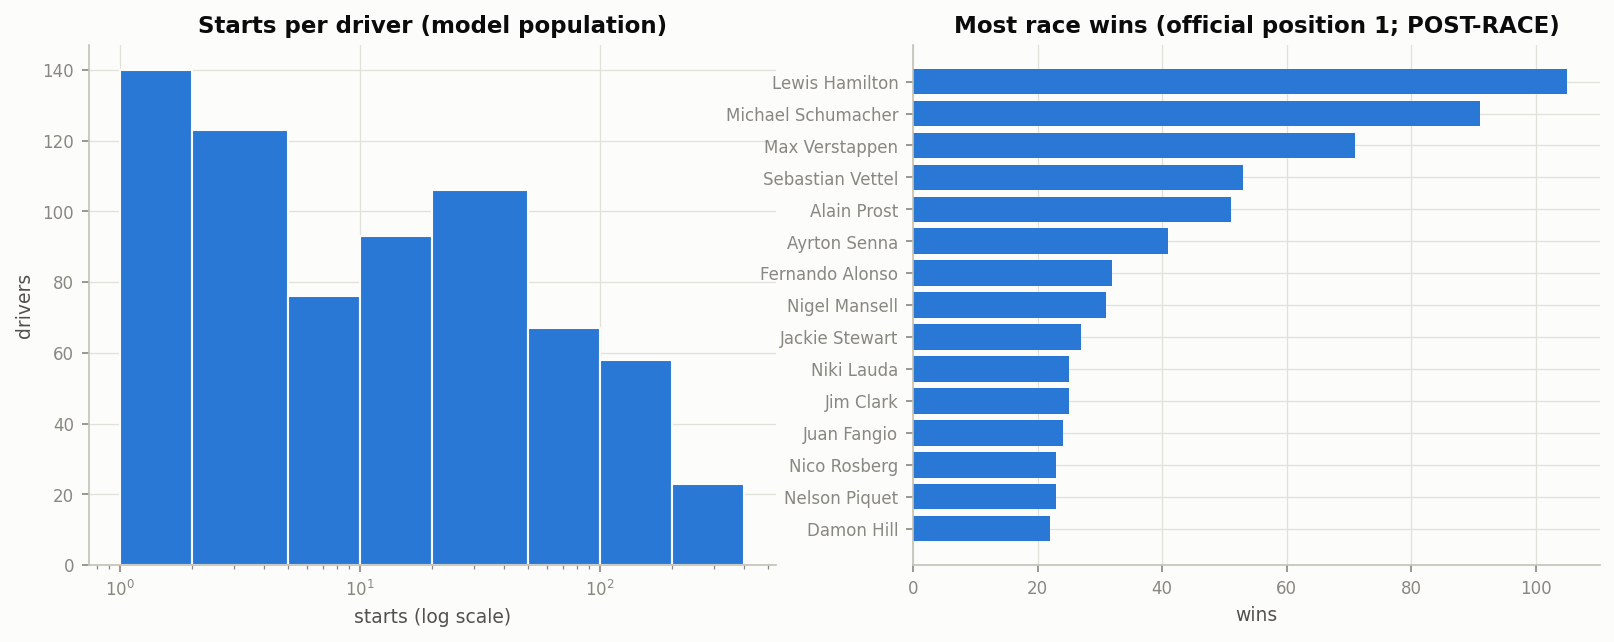

In [20]:
fig("eda_12_drivers")

Shared drives: 29 drivers had a multi-entry race (P-01) and 66 have shared-position rows (P-02), all 1950–1964. 62 drivers appear only in season lists and never in any result.

## 6. Constructors (API ids, not merged: P-09)

In [21]:
tbl("eda_constructor_stats").head(12)

,constructor_id,name,first_season,last_season,seasons,races_entered,starts,race_wins,podium_finishes,dnfs,points_all_entries,dnf_rate_pct
0,ferrari,Ferrari,1950,2025,76,1122,2431,248,846,622,11451.27,25.586
1,mclaren,McLaren,1968,2025,56,951,1938,199,542,490,7797.50,25.284
2,mercedes,Mercedes,1954,2025,18,341,697,131,310,72,8154.64,10.330
3,red_bull,Red Bull,2005,2025,21,417,831,130,297,124,8083.00,14.922
4,williams,Williams,1975,2025,50,863,1702,114,316,439,3765.00,25.793
5,team_lotus,Team Lotus,1958,1994,27,390,816,45,114,377,995.00,46.201
6,renault,Renault,1977,2020,24,400,780,35,103,250,1777.00,32.051
7,benetton,Benetton,1986,2001,16,260,519,27,102,177,861.50,34.104
8,tyrrell,Tyrrell,1970,1998,29,431,843,23,77,360,711.00,42.705
9,brabham,Brabham,1962,1992,22,300,614,23,78,312,631.00,50.814


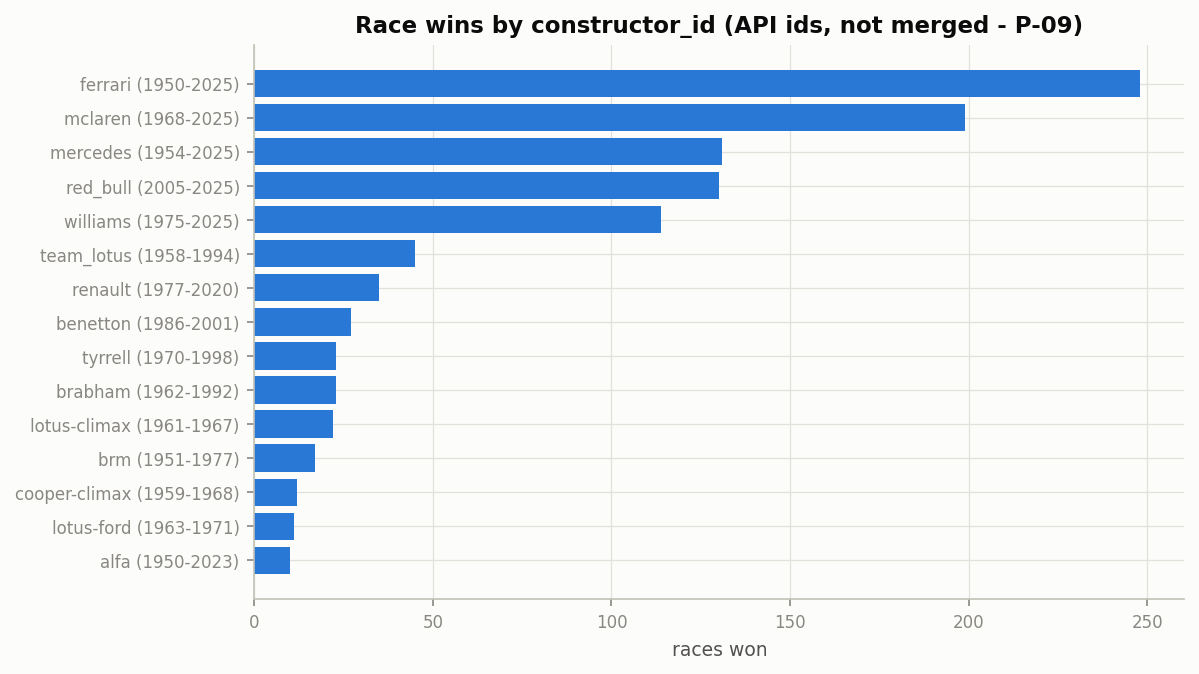

In [22]:
fig("eda_13_constructors")

## 7. Qualifying

In [23]:
tbl("eda_qualifying_coverage")

,season,races,races_with_qualifying,qualifying_rows,q1_present_pct,q2_present_pct,q3_present_pct,race_coverage_pct,format_in_data
0,1990,16,0,0,NaN,NaN,NaN,0.00,no qualifying data
1,1991,16,0,0,NaN,NaN,NaN,0.00,no qualifying data
2,1992,16,0,0,NaN,NaN,NaN,0.00,no qualifying data
3,1993,16,0,0,NaN,NaN,NaN,0.00,no qualifying data
4,1994,16,15,392,99.74,0.00,0.00,93.75,single session (Q1)
5,1995,17,17,418,94.26,0.00,0.00,100.00,single session (Q1)
6,1996,16,7,148,97.97,0.00,0.00,43.75,single session (Q1)
7,1997,17,10,220,99.55,0.00,0.00,58.82,single session (Q1)
8,1998,16,7,153,98.69,0.00,0.00,43.75,single session (Q1)
9,1999,16,3,65,98.46,0.00,0.00,18.75,single session (Q1)


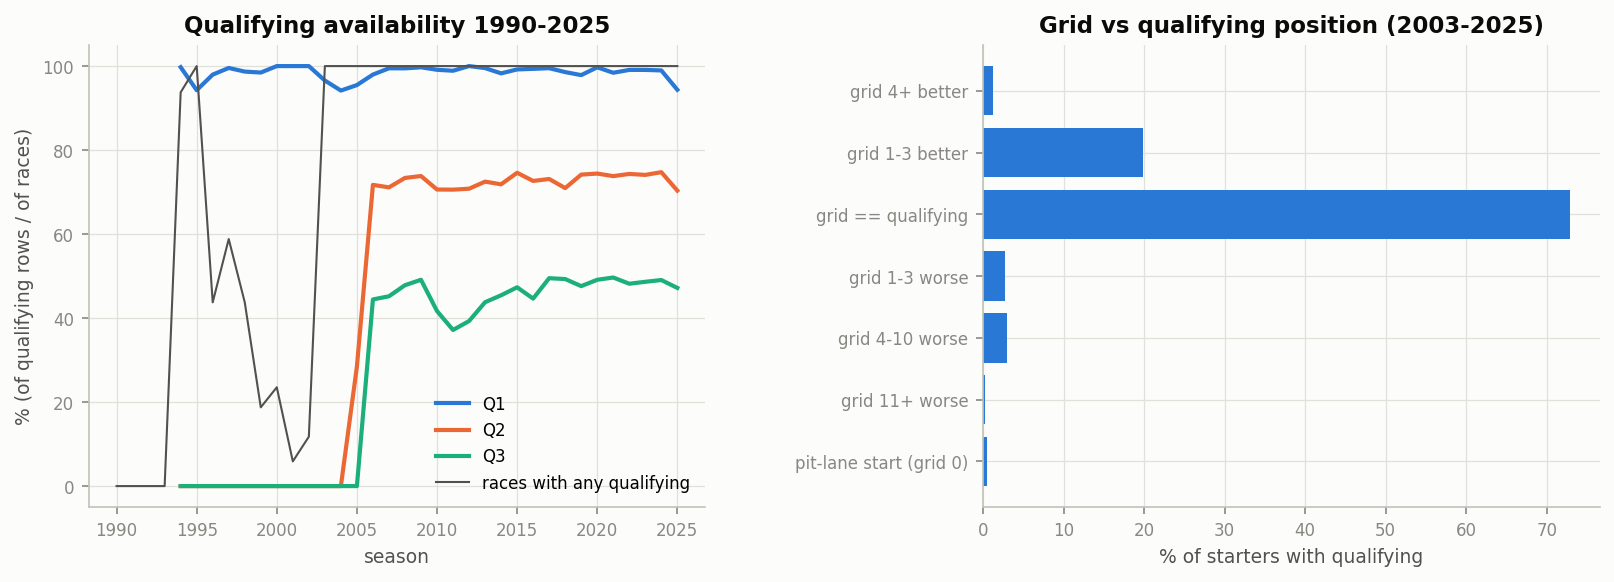

In [24]:
fig("eda_11_qualifying")

In [25]:
tbl("eda_qualifying_vs_grid")

,grid_minus_qualifying_position,rows,share_pct
0,grid 4+ better,119,1.271
1,grid 1-3 better,1855,19.812
2,grid == qualifying,6829,72.936
3,grid 1-3 worse,260,2.777
4,grid 4-10 worse,277,2.958
5,grid 11+ worse,23,0.246
6,pit-lane start (grid 0),48,0.513


In [26]:
tbl("eda_qualifying_position_outcomes").head(10)

,qualifying_position,starters,win_rate_pct,podium_rate_pct,mean_official_position,dnf_rate_pct
0,1,450,52.889,79.111,3.562,8.222
1,2,450,23.333,64.444,4.709,8.444
2,3,450,10.444,51.111,5.800,11.556
3,4,451,4.656,34.368,6.062,9.534
4,5,452,2.655,23.894,7.469,13.717
5,6,450,2.000,14.000,8.213,13.333
6,7,448,1.339,9.375,9.123,15.402
7,8,451,0.443,3.769,10.031,15.965
8,9,451,0.443,3.548,10.683,19.956
9,10,449,0.891,3.786,10.833,16.927


**Reading:** the transition is clear: no qualifying data before 1994, partial 1994–2002, complete from 2003; Q2 from 2005 and Q3 from 2006. From 2003, 73% of starters start exactly where they qualified. 20% start 1–3 places **better** (someone ahead got a penalty), 6% worse (their own penalty), and 0.5% from the pit lane. Qualifying position and grid are almost the same information (Spearman 0.97).

## 8. Grid

In [27]:
tbl("eda_grid_zero")

grid_status,era,non_starter,pit_lane_start,unknown,total_grid_zero,share_of_era_rows_pct
0,1950-1969,143,0,0,143,3.579
1,1970-1989,38,0,10,48,0.646
2,1990-2009,14,0,6,20,0.265
3,2010-2025,7,48,1,56,0.810


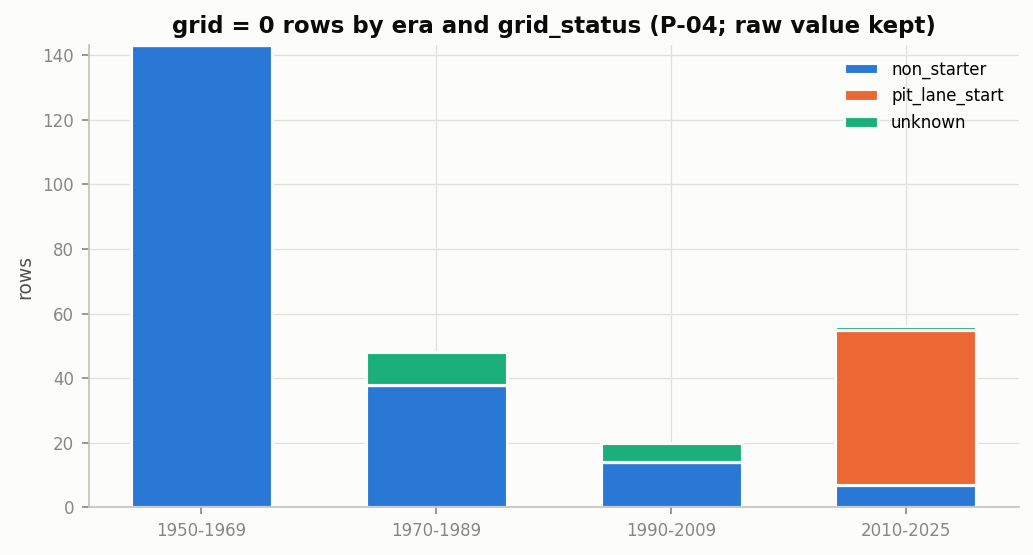

In [28]:
fig("eda_10_grid_zero_by_era")

In [29]:
tbl("eda_grid_vs_finish").query('grid <= 5')

,era,grid,starters,win_rate_pct,podium_rate_pct,mean_official_position,median_official_position,dnf_rate_pct
0,all,1,1132,43.728,65.106,5.397,2.0,21.290
1,all,2,1128,23.936,56.915,6.379,3.0,22.074
2,all,3,1134,12.346,46.825,7.348,4.0,25.220
3,all,4,1138,6.063,34.622,7.974,5.0,26.889
4,all,5,1131,4.244,25.022,8.920,6.0,29.973
20,1950-1969,1,172,40.698,51.744,5.837,3.0,30.233
21,1950-1969,2,168,25.595,51.190,6.696,3.0,33.333
22,1950-1969,3,172,13.953,40.116,7.750,5.0,37.209
23,1950-1969,4,172,6.395,34.884,7.913,5.0,38.953
24,1950-1969,5,166,2.410,32.530,7.982,5.0,39.157


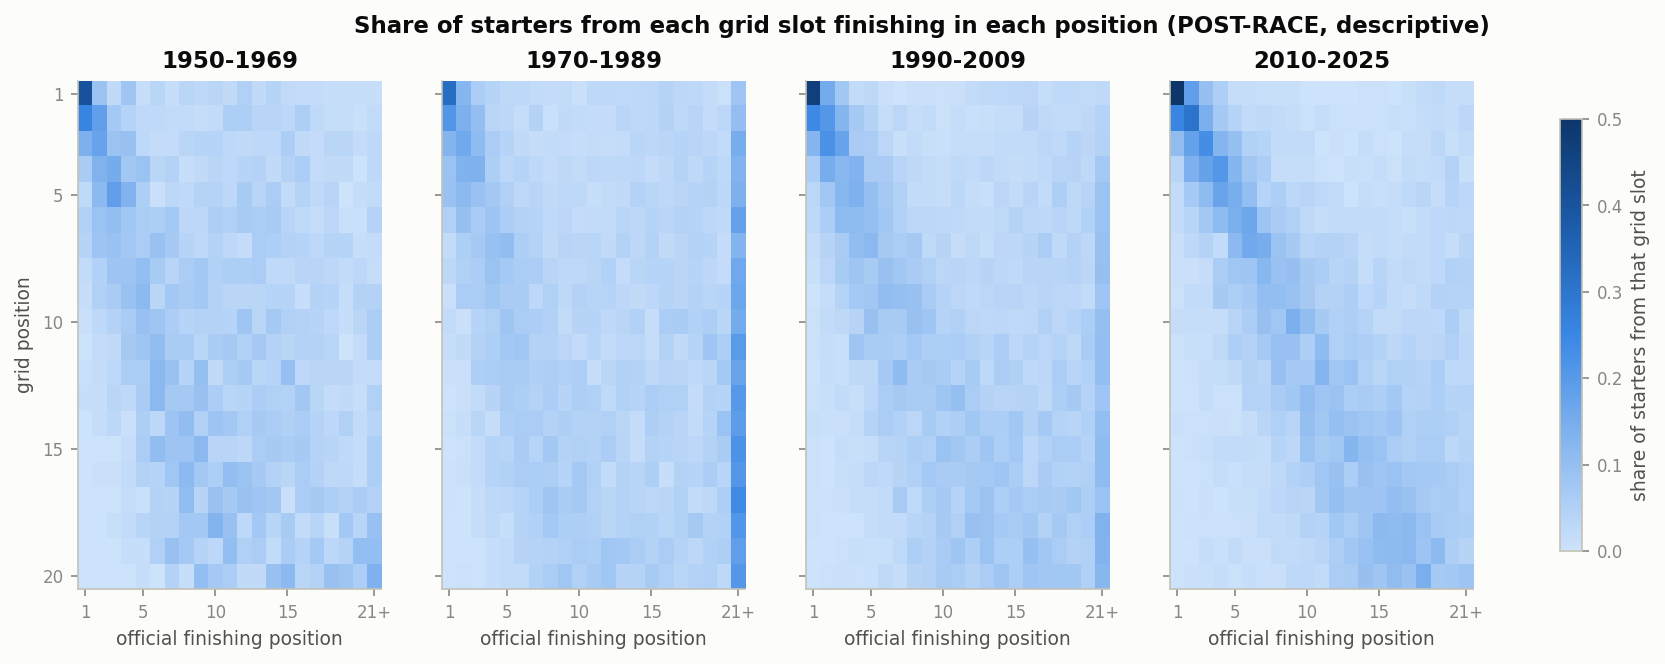

In [30]:
fig("eda_07_grid_vs_finish_heatmaps")

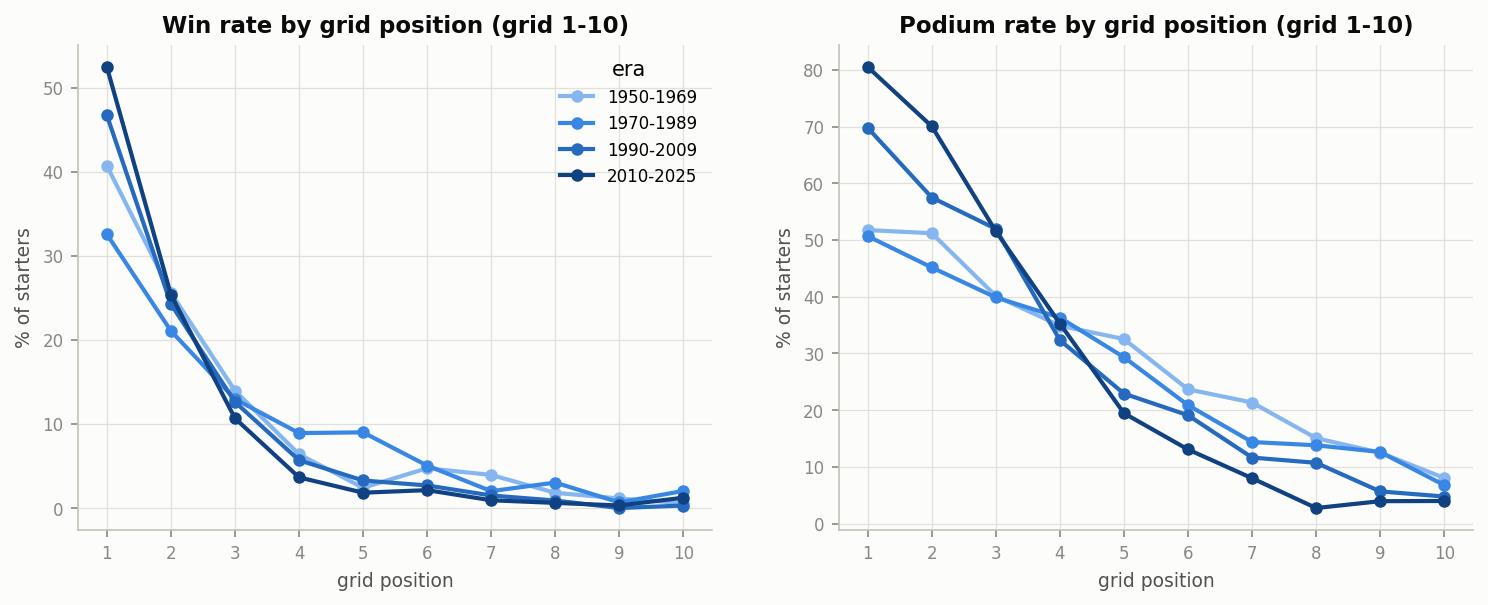

In [31]:
fig("eda_08_win_podium_rate_by_grid")

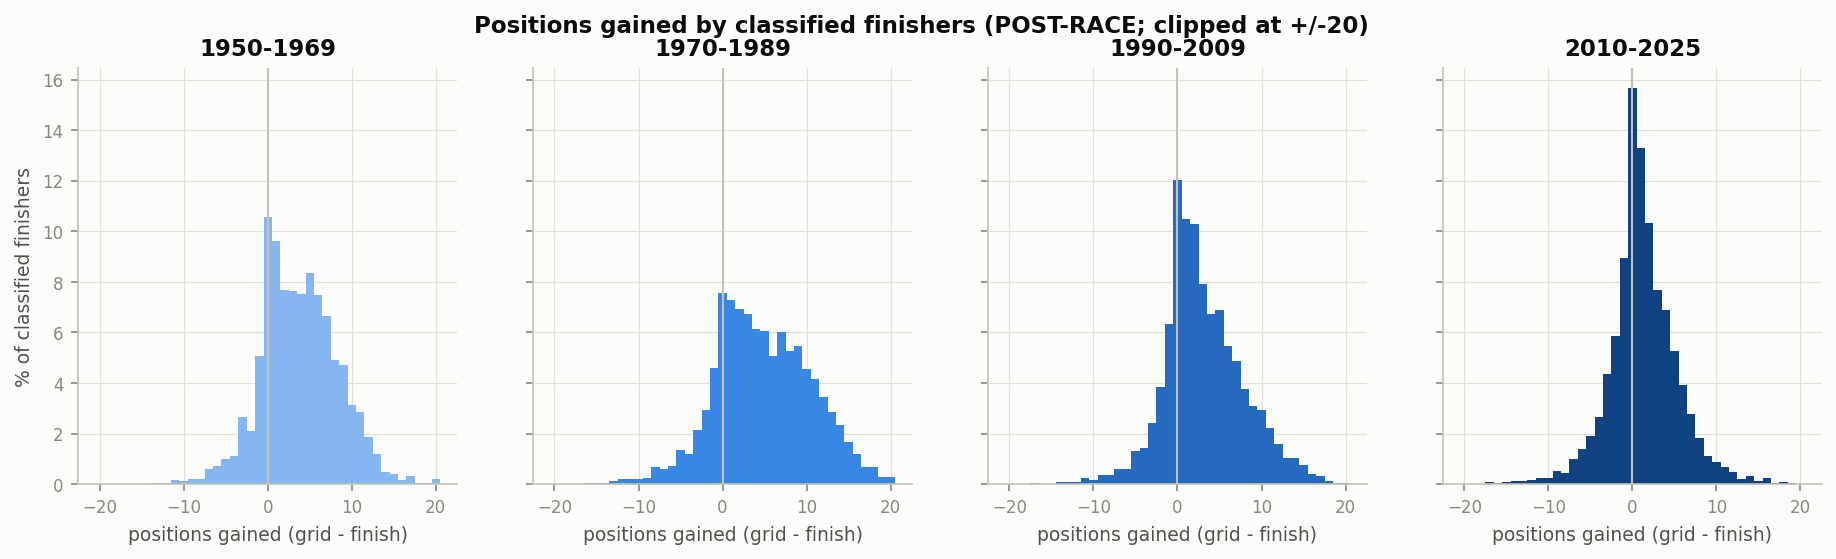

In [32]:
fig("eda_09_position_change_by_era")

**Reading:** grid = 0 means non-starter before 1970 (143 rows) and mostly pit-lane start after 2010 (48 of 56). The grid → finish relationship has **strengthened**: pole converts to a win 33% (1970–89) → 47% (1990–2009) → 52% (2010–2025), and podium from pole 51% → 80%. In older eras the "21+" column (retirements placed at the back) dominates the lower grid.

## 9. Weather (reanalysis; start-time basis differs by era)

In [33]:
tbl("eda_weather_distribution").query("group == 'all' and window == 'race'")

,window,variable,group,races,mean,std,min,p05,median,p95,max
64,race,temp_mean_c,all,1138,21.628,5.009,6.633,13.695,21.383,29.948,36.900
72,race,humidity_mean_pct,all,1138,58.587,16.121,8.333,32.667,58.166,85.000,99.000
80,race,precip_sum_mm,all,1138,0.307,1.064,0.000,0.000,0.000,1.700,16.900
88,race,rain_sum_mm,all,1138,0.307,1.064,0.000,0.000,0.000,1.700,16.900
96,race,cloud_mean_pct,all,1138,58.432,35.985,0.000,0.000,66.333,100.000,100.000
104,race,wind_speed_mean_kmh,all,1138,12.884,6.754,0.800,3.700,11.967,25.667,39.867
112,race,wind_dir_mean_deg,all,1138,199.515,98.397,1.000,25.850,206.100,343.705,360.000
120,race,weather_code_max,all,1138,18.513,24.473,0.000,0.000,3.000,61.000,65.000


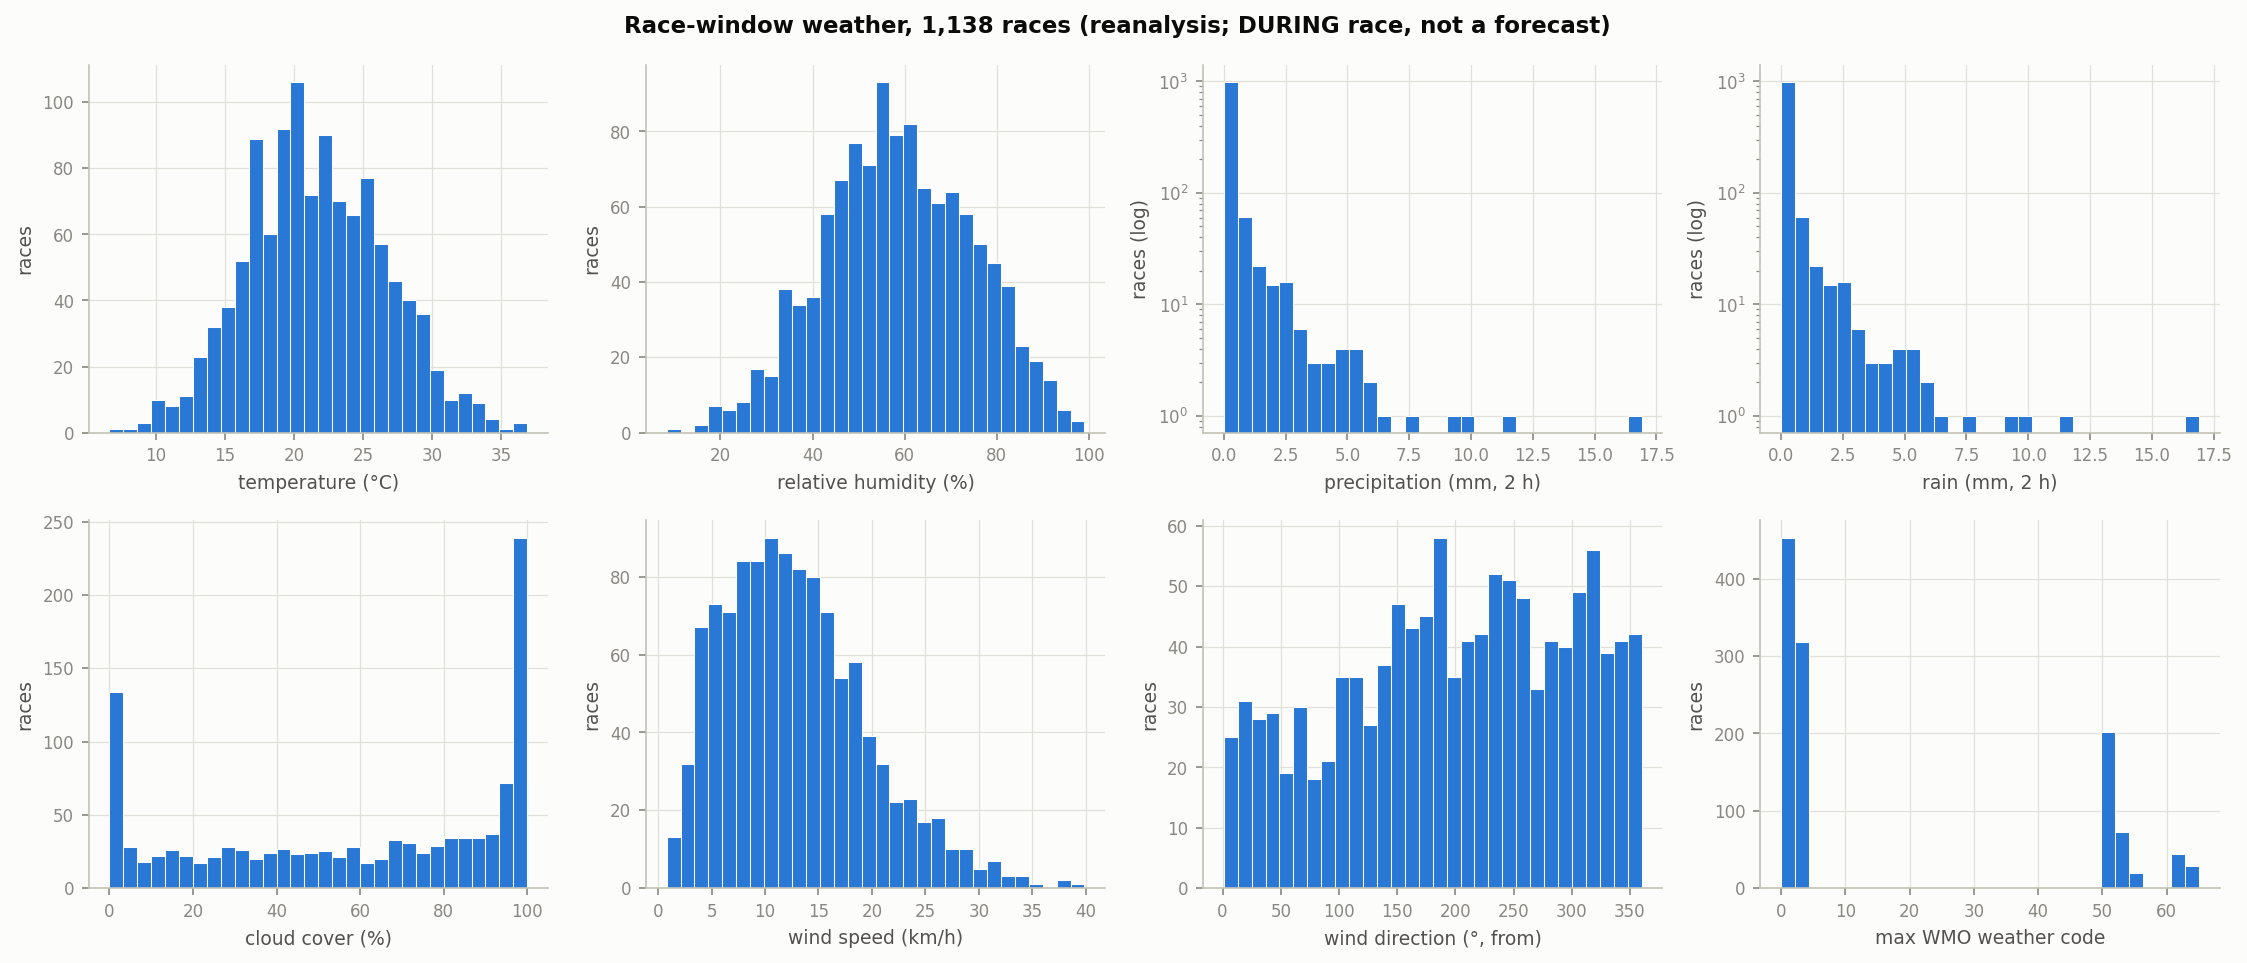

In [34]:
fig("eda_14_weather_distributions")

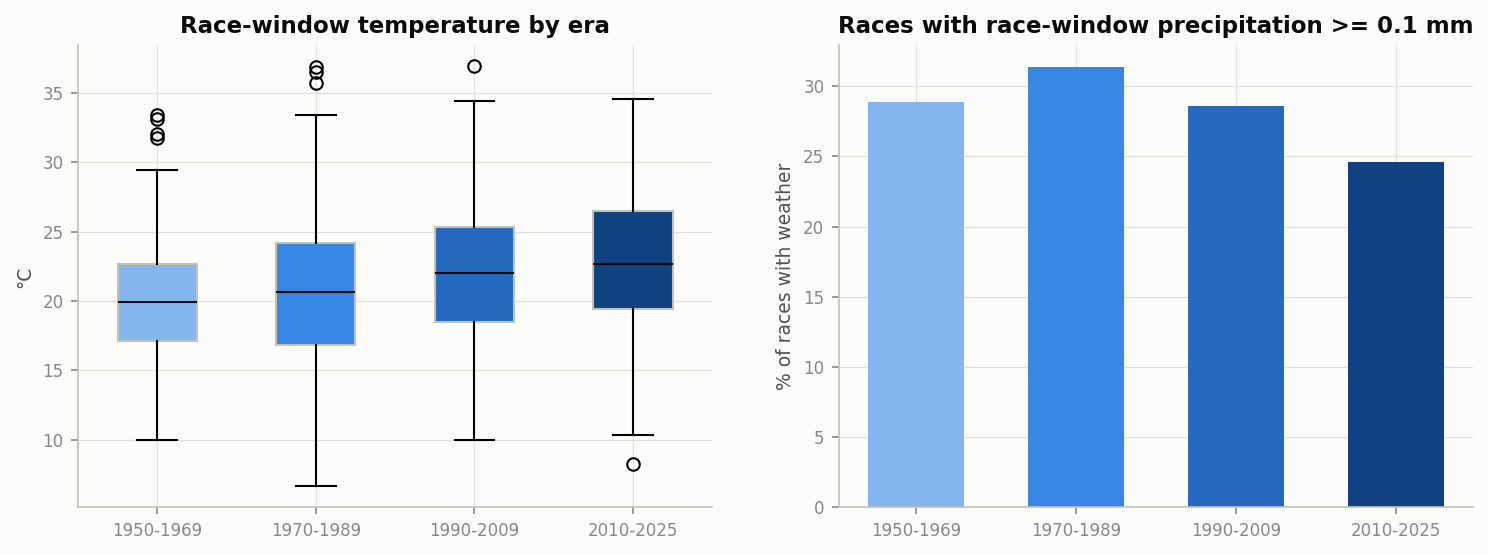

In [35]:
fig("eda_15_weather_by_era")

In [36]:
tbl("eda_weather_prestart_vs_race")

,variable,races,mean_race_minus_prestart,median_diff,mean_abs_diff,spearman_prestart_vs_race,both_dry,prestart_wet_only,race_wet_only,both_wet
0,temp_mean_c,1138,0.8245,1.0,1.3513,0.9622,NaN,NaN,NaN,NaN
1,humidity_mean_pct,1138,-3.0015,-4.0,6.3946,0.8871,NaN,NaN,NaN,NaN
2,precip_sum_mm,1138,0.0574,0.0,0.3249,0.6243,NaN,NaN,NaN,NaN
3,cloud_mean_pct,1138,1.8761,0.0,14.3723,0.8311,NaN,NaN,NaN,NaN
4,wind_speed_mean_kmh,1138,0.6004,0.6,2.3832,0.8787,NaN,NaN,NaN,NaN
5,precip >= 0.1 mm (wet window),1138,NaN,NaN,NaN,NaN,719.0,98.0,98.0,223.0


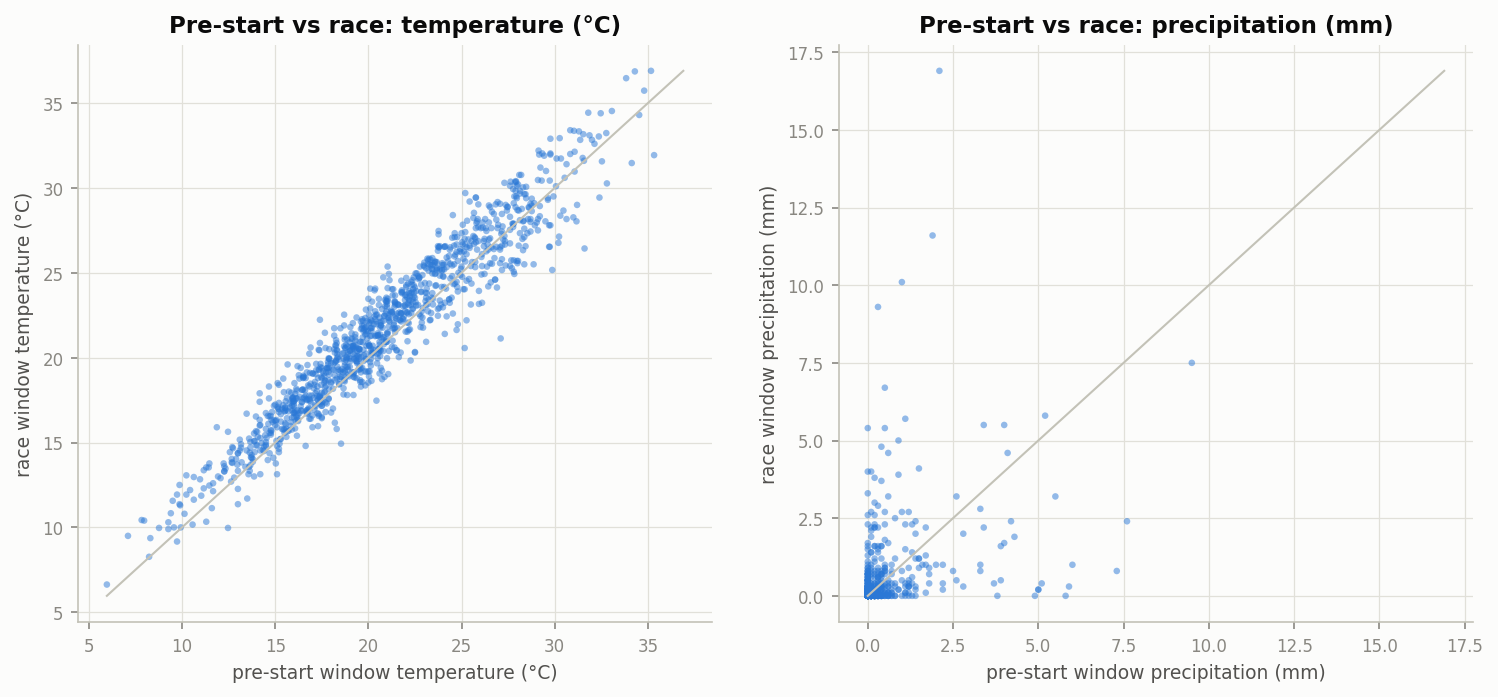

In [37]:
fig("eda_16_prestart_vs_race_weather")

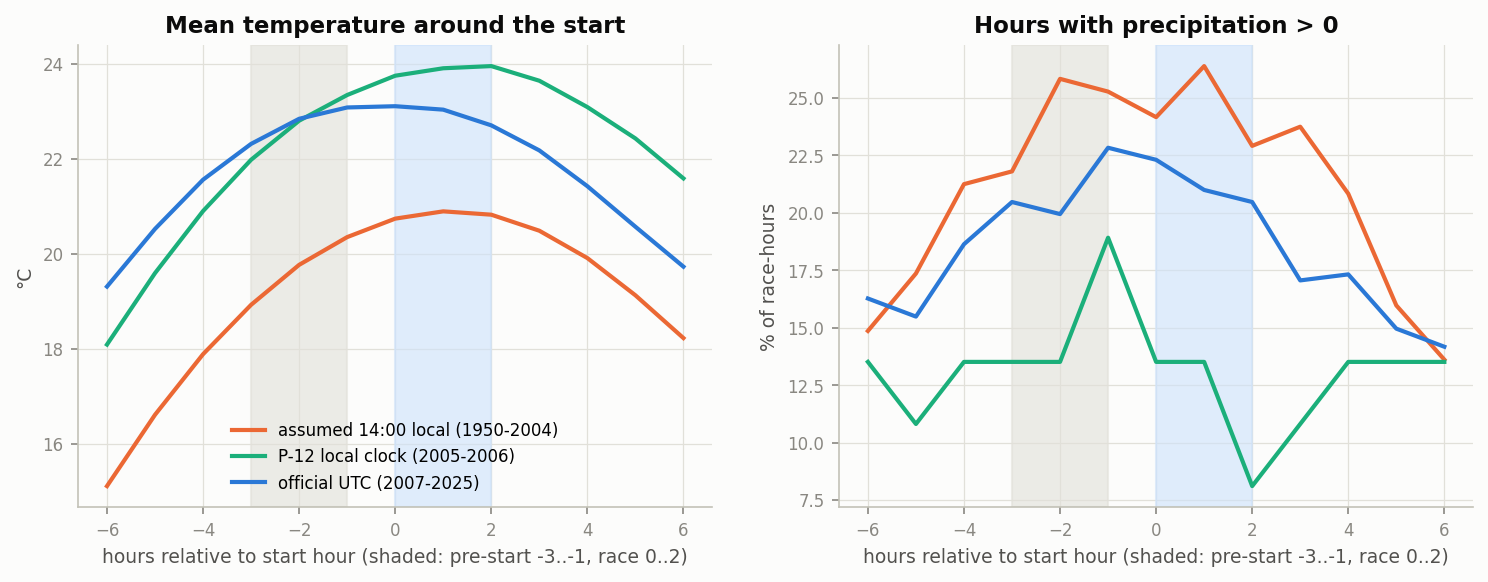

In [38]:
fig("eda_18_hourly_profile")

### Evidence for a later wet/dry threshold (no threshold is chosen here)

In [39]:
tbl("eda_weather_wet_evidence")

,race_window_precip_mm,races,share_pct,races_prestart_same_threshold,races_2007_2025 (official start),mean_dnf_rate_pct (these races),mean_dnf_rate_pct (other races),mean_abs_position_change (these),mean_abs_position_change (other),pole_win_pct (these),pole_win_pct (other)
0,> 0,321,28.207,321.0,99.0,36.414,34.021,4.698,4.446,41.009,45.117
1,>= 0.1,321,28.207,321.0,99.0,36.414,34.021,4.698,4.446,41.009,45.117
2,>= 0.2,263,23.111,258.0,76.0,36.993,34.006,4.753,4.446,40.000,45.150
3,>= 0.5,158,13.884,134.0,47.0,36.511,34.404,4.615,4.502,40.385,44.536
4,>= 1.0,93,8.172,82.0,23.0,38.610,34.348,4.817,4.491,37.363,44.541
5,>= 2.0,53,4.657,36.0,14.0,37.919,34.539,4.732,4.507,26.923,44.786
6,>= 5.0,13,1.142,11.0,2.0,41.421,34.618,4.479,4.518,38.462,44.025
7,weather_code_max >= 51 (drizzle or worse),367,32.250,NaN,NaN,35.800,34.171,4.664,4.448,42.149,44.823
8,weather_code_max >= 61 (rain or worse),73,6.415,NaN,NaN,36.129,34.598,4.727,4.503,34.722,44.592


In [40]:
tbl("eda_weather_wet_by_era")

,era,race_window_precip_mm,wet_races,dry_races,wet_share_pct,dnf_rate_pct_wet,dnf_rate_pct_dry,mean_abs_position_change_wet,mean_abs_position_change_dry,pole_win_pct_wet,pole_win_pct_dry
0,1950-1969,>= 0.1,50,123,28.902,44.480,45.226,4.402,4.755,47.917,39.831
1,1950-1969,>= 0.5,26,147,15.029,44.550,45.092,4.138,4.744,44.000,41.844
2,1950-1969,>= 2.0,9,164,5.202,41.384,45.209,3.921,4.693,22.222,43.312
3,1970-1989,>= 0.1,94,206,31.333,47.068,48.597,6.075,6.076,31.522,33.010
4,1970-1989,>= 0.5,46,254,15.333,45.301,48.628,5.925,6.103,33.333,32.411
5,1970-1989,>= 2.0,13,287,4.333,46.886,48.174,6.121,6.074,25.000,32.867
6,1990-2009,>= 0.1,96,240,28.571,37.858,36.441,4.699,4.348,42.708,48.319
7,1990-2009,>= 0.5,50,286,14.881,37.233,36.779,4.534,4.433,40.000,47.887
8,1990-2009,>= 2.0,22,314,6.548,39.274,36.676,4.669,4.433,27.273,48.077
9,2010-2025,>= 0.1,81,248,24.620,17.358,14.015,3.284,3.034,45.679,54.656


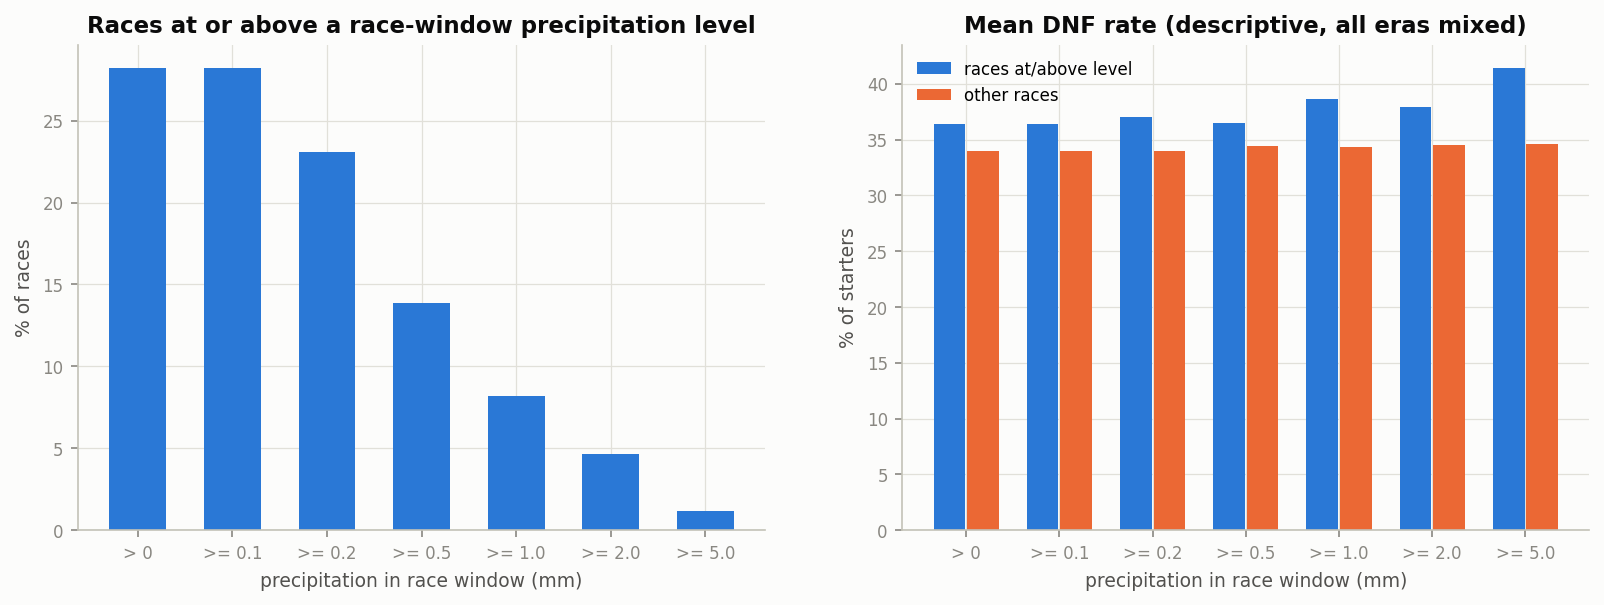

In [41]:
fig("eda_17_wet_threshold_evidence")

**Reading:**
- Precipitation resolution is 0.1 mm, so "> 0" and "≥ 0.1 mm" are the same 321 races (28%). ≥ 0.5 mm: 158 races (14%); ≥ 2 mm: 53 races (4.7%).
- Pre-start and race-window conditions agree strongly for temperature (ρ 0.96) and wind (0.88), but only moderately for precipitation (ρ 0.62): 98 races were wet only before the start and 98 only during the race.
- **Within eras 1990–2025**, wet races (≥ 0.5–2 mm) show higher DNF rates (e.g. 18.5% vs 14.4% in 2010–25) and lower pole-win rates (27–47% vs 48–53%). **1950–1989 shows no clear signal**, consistent with the assumed 14:00 start times (imprecise windows) and small samples. Pooled comparisons mix eras and understate the effect.
- The hourly profile shows the expected daytime temperature peak around the (assumed or official) start hour.

## 10. Era comparison

In [42]:
tbl("eda_era_summary").T

,0,1,2,3
era,1950-1969,1970-1989,1990-2009,2010-2025
seasons,20,20,20,16
races,184,300,336,329
eligible_races,173,300,336,329
model_rows,3356,7364,7476,6870
mean_starters_per_race,19.399,24.547,22.25,20.881
drivers_per_season,46.75,39.8,28.35,23.125
constructors_per_season,12.3,16.25,12.1,10.562
"dnf_rate_pct (started, not classified)",45.381,48.099,37.681,14.949
disqualified_pct,0.417,1.1,0.615,0.291


## 11. Correlations (descriptive only, not feature selection)

In [43]:
tbl("eda_correlations")

,pair,population,n,spearman,pearson,timing_of_variables
0,grid vs official position,"model population, grid > 0",25001,0.4640,0.4525,pre-race vs POST-RACE
1,grid vs official position (1950-1969),"model population, grid > 0",3356,0.4223,0.4370,pre-race vs POST-RACE
2,grid vs official position (1970-1989),"model population, grid > 0",7354,0.3258,0.3230,pre-race vs POST-RACE
3,grid vs official position (1990-2009),"model population, grid > 0",7470,0.4542,0.4462,pre-race vs POST-RACE
4,grid vs official position (2010-2025),"model population, grid > 0",6821,0.6328,0.6250,pre-race vs POST-RACE
5,qualifying position vs official position (2003-2025),"model population, has qualifying",9363,0.6211,0.6169,pre-race vs POST-RACE
6,qualifying position vs grid (2003-2025),"has qualifying, grid > 0",9315,0.9685,0.9676,pre-race vs pre-race
7,laps vs points,model population,25066,0.4007,0.2741,POST-RACE vs POST-RACE
8,laps vs official position,model population,25066,-0.6355,-0.6793,POST-RACE vs POST-RACE
9,laps completed ratio vs official position,model population,25066,-0.8270,-0.7602,POST-RACE vs POST-RACE


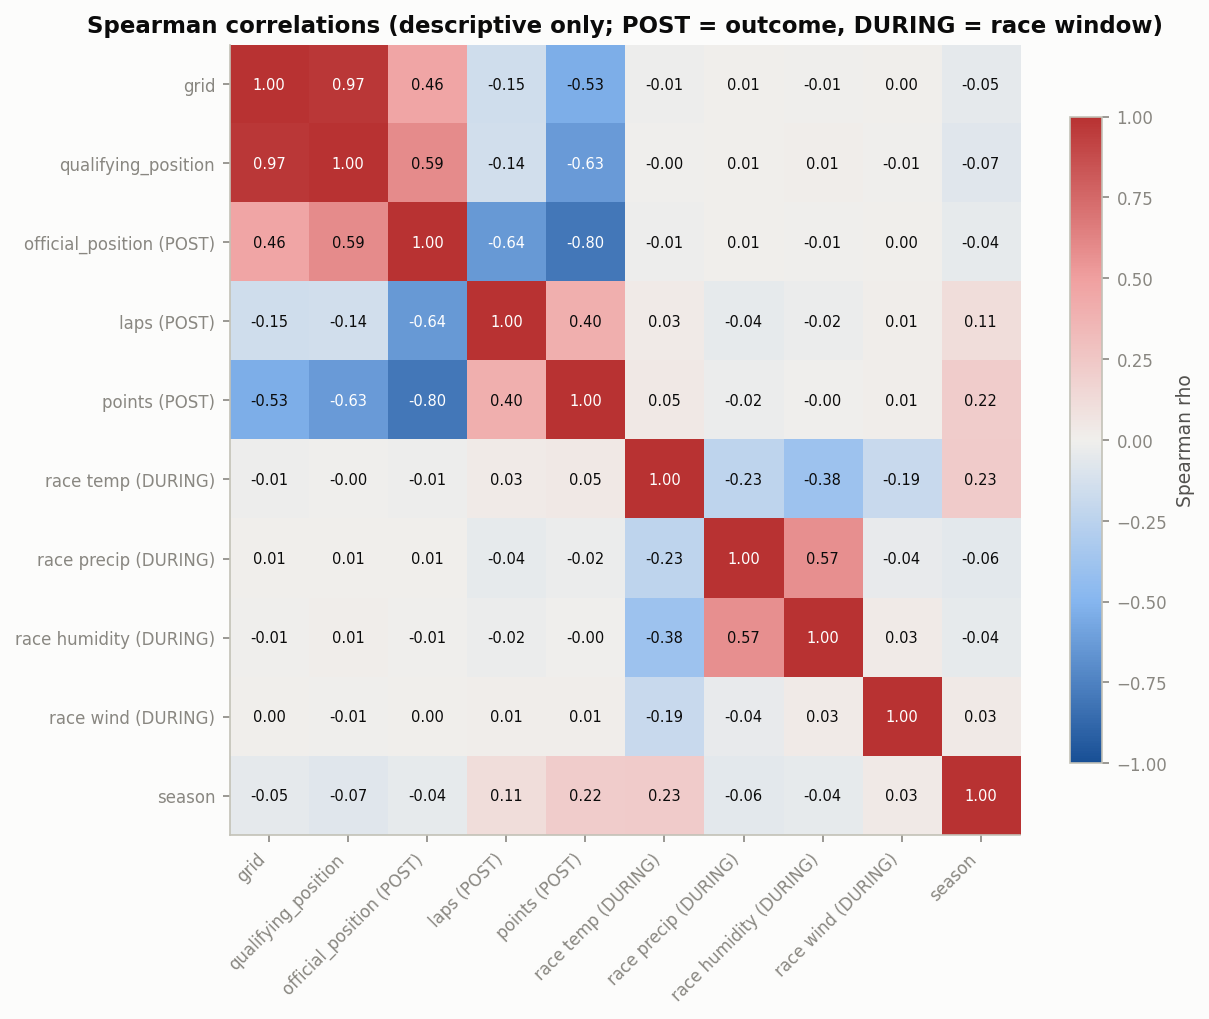

In [44]:
fig("eda_19_correlation_matrix")

**Reading:** grid vs official position ρ = 0.46 overall, rising from 0.33 (1970–89) to 0.63 (2010–25). Qualifying position vs position (2003–25) ρ = 0.62. Laps/points vs position are strong but are **outcome vs outcome** and say nothing about prediction. Race-level weather correlations with DNF rate are weak when pooled (|ρ| ≤ 0.17; warmer races had fewer DNFs, confounded by era).

## 12. Anomalies (not corrected)

In [45]:
tbl("eda_anomaly_summary")

,anomaly,severity,policy,rows,races,seasons,possible_explanation,handle_later
0,ambiguous_status,known_handled,P-07,24,19,1952-2023,"'Withdrew' after laps, or classified 'Withdrew'/'Not classified'",Handled by P-07
1,constructor_id_reused_after_gap,known_handled,P-09,20,0,,brand IDs reused decades apart (e.g. mercedes 1954-55 / 2010+),Handled by P-09; use recent-window constructor history later
2,disqualified_with_numeric_positionText,known_handled,P-05,3,2,2023-2024,DSQ recorded with a numeric position code,Handled by P-05 (status used)
3,driver_without_dob_or_nationality,review,,14,0,2025-2025,little-known entrants without dob in the API,Only if driver age is used
4,grid_zero_started_no_laps,known_handled,P-04,17,17,1981-2017,started category but 0 laps: start position unknown,Handled by P-04 (grid unknown)
5,imputed_start_time_limitation,known_handled,,1,0,,no official start times before 2005,Limitation: 14:00 local assumed
6,indianapolis_500_race,known_handled,P-11,11,11,1950-1960,Indianapolis 500 was a championship round 1950-1960,Handled by P-11 (excluded)
7,laps_order_exception,known_handled,P-10,16,8,1951-1992,R rows with more laps placed below fewer laps (8 races),Handled by P-10 (official order kept)
8,later_session_time_without_q1,review,P-03,2,2,2024-2024,Q2/Q3 time without Q1 (source gap),Low: only if qualifying times are used
9,model_population_positions_not_consecutive,review,P-08/P-10,45,45,1950-2024,"gaps, secondary entries, shared positions, non-starters in between",YES: same target decision


## 13. Summary for the target/feature discussion (no decisions taken)

**Clearly POST-RACE (never inputs):** position, position_text, points, laps, status, time, fastest-lap fields, result categories, retired_while_classified, shared_position flags, is_primary_entry, laps_order_exception, and race-window weather (only as an oracle proxy).

**Candidates to investigate later (NOT a selected feature set):** grid position and pit-lane start; qualifying position/gap (2003+, missing earlier); sprint result (2021+); pre-race history of the driver/constructor (computed strictly from earlier races); circuit history; season/round context; pre-start weather (reanalysis, not a forecast); era.

**Open questions for the next step:** official position vs rank among starters as the position target (45 races with non-consecutive positions); the wet/dry threshold; the training window (strong drift across eras: DNF rate, grid → finish relationship, points systems).